# Exploratory Data Analysis (EDA) – Apartment Rent Prices in Thessaloniki

This notebook walks through the exploratory data analysis (EDA) phase of a machine-learning project whose goal is to predict monthly rent prices for apartments in Thessaloniki, Greece. The dataset was sourced from **spitogatos.gr**, a popular Greek real-estate listing platform.

**Why EDA matters:** Before feeding any data into a model we need to understand its structure, quality, and the relationships between variables. EDA helps us spot data quality issues, identify promising predictors, and inform decisions about feature engineering and outlier treatment that will be carried out in later notebooks.

Here are the features we will explore:
1. **listingId:** Unique listing ID
2. **listingType**: rent or sale
3. **propertyType**: apartment, house, maisonette, studio, etc.
4. **price**: Asking price in EUR
5. **pricePerSqm**: Price per square meter
6. **areaSqm**: Living area in square meters
7. **rooms**: Number of rooms
8. **bathrooms**: Number of bathrooms
9. **kitchens**: Number of kitchens
10. **livingRooms**: Number of living rooms
11. **floor**: Floor number
12. **location**: Neighborhood and city (e.g. "Plaka (Athens - Center)")
13. **isNewDevelopment** Whether it's a new construction project
14. **yearBuilt**: Year of construction
15. **renovationYear**: Year of last renovation
16. **energyClass**: Energy efficiency class (A+ to H)
17. **elevator**: Has elevator
18. **airConditioning**: Has AC
19. **fireplace**: Has fireplace
20. **storage**: Has storage room
21. **balcony**: Has balcony
22. **garden**: Has garden
23. **pool**: Has swimming pool
24. **hasParking**: Has parking
25. **openParkingSpots**: Number of open parking spots
26. **closedParkingSpots**: Number of garage/closed spots
27. **alarm**: Has alarm system
28. **furnished**: Furnishing status
29. **petsAllowed**: Pets allowed
30. **view**: Has view
31. **solarHeater**: Has solar water heater

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [2]:
df = pd.read_csv("spitogatos.csv")
df.head()


,listingId,airConditioning,alarm,areaSqm,balcony,bathrooms,closedParkingSpots,elevator,energyClass,fireplace,...,pool,price,pricePerSqm,propertyType,renovationYear,rooms,solarHeater,storage,view,yearBuilt
0,20304396,True,False,47,False,1.0,NaN,True,C,False,...,False,600,12.77,apartment,2026.0,NaN,False,False,True,1975.0
1,19956518,True,False,25,False,1.0,NaN,True,B,False,...,False,530,21.20,apartment,2023.0,NaN,False,False,True,1982.0
2,18383741,False,False,60,False,1.0,NaN,True,D,False,...,False,510,8.50,apartment,NaN,1.0,False,False,True,1978.0
3,20242029,True,False,60,False,1.0,NaN,True,F,False,...,False,330,5.50,apartment,NaN,1.0,False,False,True,1978.0
4,20055845,True,False,75,False,1.0,NaN,True,C,False,...,False,620,8.27,apartment,NaN,2.0,False,False,True,1981.0


In [3]:
df.shape


(2480, 31)

In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2480 entries, 0 to 2479
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   listingId           2480 non-null   int64  
 1   airConditioning     2392 non-null   object 
 2   alarm               2303 non-null   object 
 3   areaSqm             2480 non-null   int64  
 4   balcony             2402 non-null   object 
 5   bathrooms           2415 non-null   float64
 6   closedParkingSpots  6 non-null      float64
 7   elevator            2418 non-null   object 
 8   energyClass         2478 non-null   object 
 9   fireplace           2313 non-null   object 
 10  floor               2480 non-null   int64  
 11  furnished           2404 non-null   object 
 12  garden              2292 non-null   object 
 13  hasParking          2329 non-null   object 
 14  isNewDevelopment    2480 non-null   bool   
 15  kitchens            2294 non-null   float64
 16  listin

## Data Quality Checks

After confirming the data loaded successfully, we need to assess its quality. Three of the most common quality issues are **missing values**, **duplicate rows**, and **columns with unusual cardinality**. Addressing these early prevents subtle bugs downstream.

- **Missing values** are expressed here as the *proportion* of `NaN` entries per column (rounded to three decimal places). Columns with a high missing rate may need imputation or removal.
- **Duplicate rows** can artificially inflate certain patterns and bias the model.
- **Unique-value counts** (`nunique`) reveal the cardinality of each feature. Features with very few unique values are typically categorical or binary, while high-cardinality features (such as IDs or free-text fields) are usually not useful as direct model inputs.


In [5]:
# Check missing values
print(round(df.isnull().sum()/len(df),3))


listingId             0.000
airConditioning       0.035
alarm                 0.071
areaSqm               0.000
balcony               0.031
bathrooms             0.026
closedParkingSpots    0.998
elevator              0.025
energyClass           0.001
fireplace             0.067
floor                 0.000
furnished             0.031
garden                0.076
hasParking            0.061
isNewDevelopment      0.000
kitchens              0.075
listingType           0.000
livingRooms           0.169
location              0.000
openParkingSpots      0.967
petsAllowed           0.894
pool                  0.076
price                 0.000
pricePerSqm           0.000
propertyType          0.000
renovationYear        0.530
rooms                 0.096
solarHeater           0.073
storage               0.082
view                  0.061
yearBuilt             0.098
dtype: float64


In [6]:
# Check duplicate values
df.duplicated().sum()


0

In [7]:
# Check unique values
df.nunique()


listingId             2480
airConditioning          2
alarm                    2
areaSqm                131
balcony                  2
bathrooms                4
closedParkingSpots       2
elevator                 2
energyClass             11
fireplace                2
floor                   15
furnished                2
garden                   2
hasParking               2
isNewDevelopment         2
kitchens                 2
listingType              1
livingRooms              3
location                64
openParkingSpots         3
petsAllowed              1
pool                     1
price                   97
pricePerSqm            616
propertyType             1
renovationYear          30
rooms                    5
solarHeater              2
storage                  2
view                     2
yearBuilt               84
dtype: int64

---

## Univariate Analysis – Categorical & Binary Features

With the basic quality checks out of the way, we move on to **univariate analysis** examining each feature individually to understand its distribution. For features that have 15 or fewer unique values (binary flags, ordinal ratings like energy class, or low-cardinality categorical variables), count plots are an effective choice because they show the frequency of every category at a glance.

The code below automatically selects all columns with ≤ 15 unique values and draws a `sns.countplot` for each. This grid view makes it easy to spot **class imbalances**, a situation where one category dominates the others, which is important to note because severely imbalanced features may contribute little predictive power or require special encoding strategies.


In [8]:
# Select features that have less than or equal to 15 unique values for analysis
features_subset1 = []
for col in df.columns:
    if df[col].nunique() <= 15:
        features_subset1.append(col)
        
print(features_subset1)
print(f"There is a total of {len(features_subset1)} features")


['airConditioning', 'alarm', 'balcony', 'bathrooms', 'closedParkingSpots', 'elevator', 'energyClass', 'fireplace', 'floor', 'furnished', 'garden', 'hasParking', 'isNewDevelopment', 'kitchens', 'listingType', 'livingRooms', 'openParkingSpots', 'petsAllowed', 'pool', 'propertyType', 'rooms', 'solarHeater', 'storage', 'view']
There is a total of 24 features


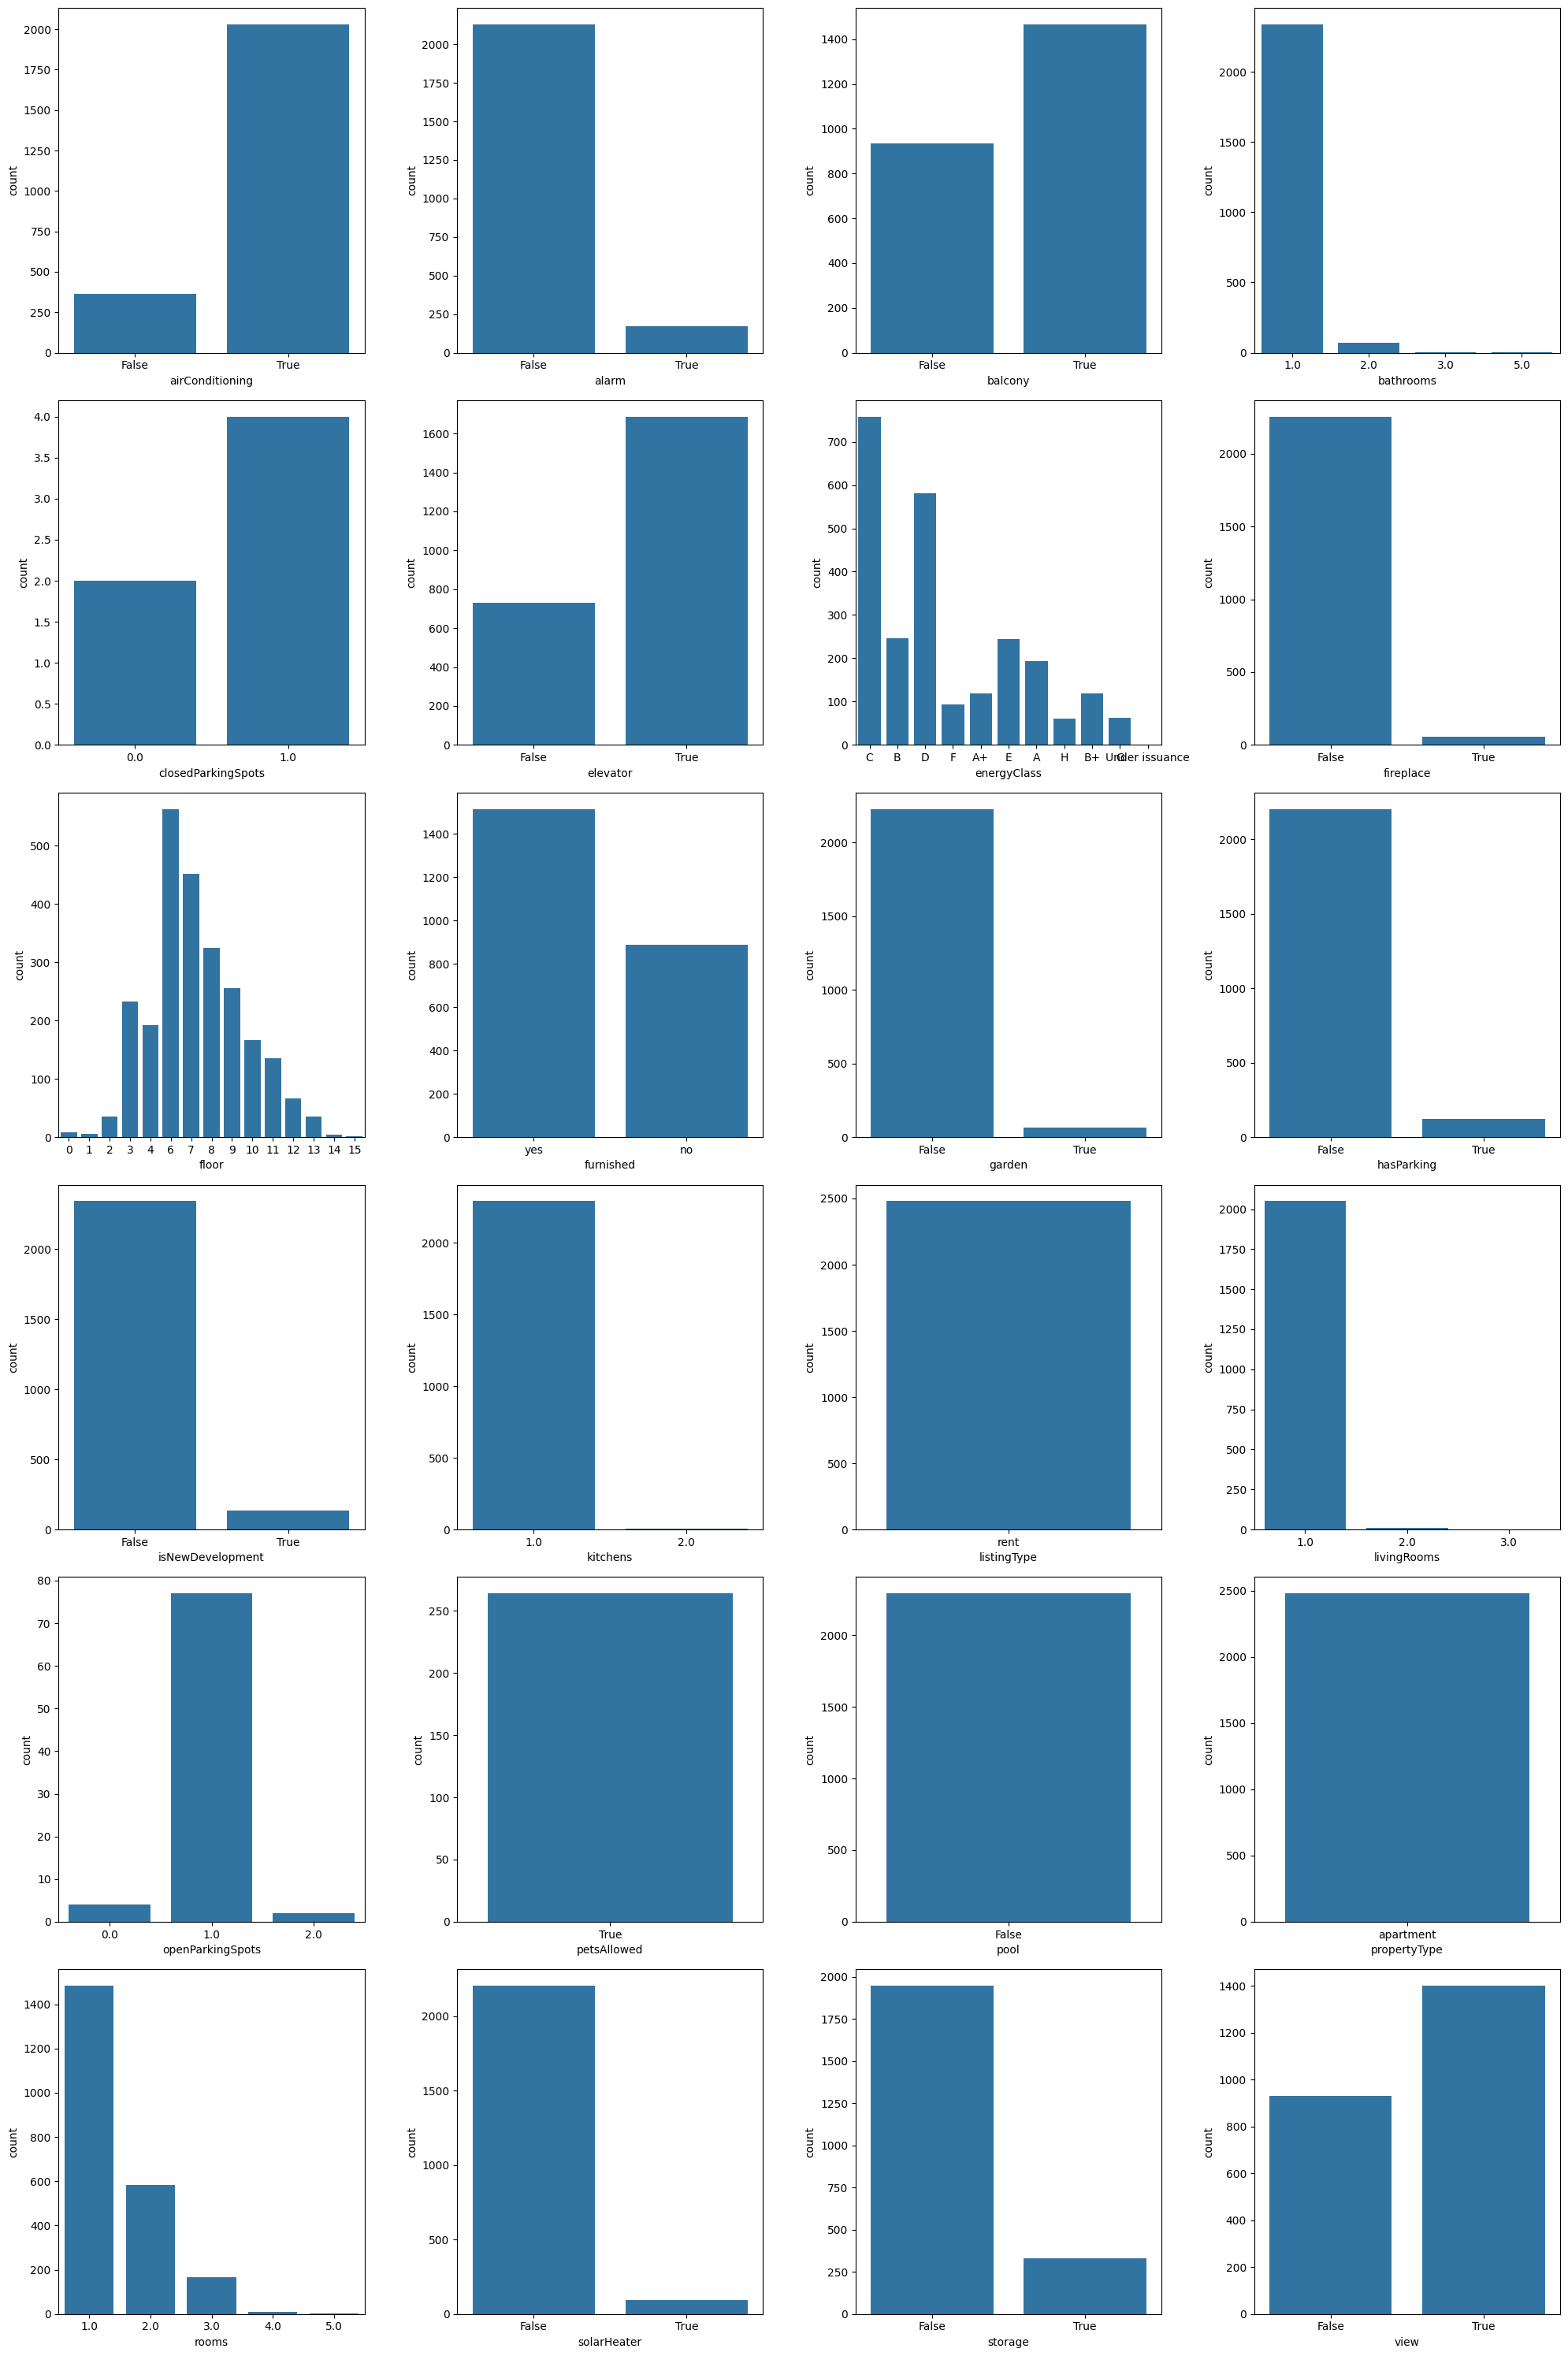

In [9]:
plt.figure(figsize=(20,30))

for i, col in enumerate(features_subset1):
    plt.subplot(6, 4, i+1)
    sns.countplot(data=df, x=col)
    plt.xlabel(col)

plt.tight_layout()
plt.show()


**Observations from the count plots:**

From the plots we can identify some major class imbalances in the distribution of certain variables. Some of the conclusions are:
- The vast majority of apartments have air conditioning.
- The vast majority of apartments do not have an alarming system.
- The number of apartments that have a balcony is greater than those they don't.
- The vast majority of apartments have only one bathroom.
- The number of apartments that have garage spots is greater than those they don't.
- The number of apartments that have an elevator is greater than those they don't. 
- Most of the apartments have C rating energy class followed by D. That indicates moderate efficiency and utility costs.
- The vast majority of apartments have fireplace.
- Most of the apartments belong to the 6th floor and above.
- The number of apartments that are furnished is greater than those they are not. 
- The vast majority of apartments don't have a garden.
- The vast majority of apartments don't have a private parking.
- The vast majority of apartments are not considered new construction projects.
- The vast majority of apartments have only one kitchen.
- The vast majority of apartments have only one living room.
- Most of the apartments have only 1 bedroom, followed by 2 and 3.
- The vast majority of apartments don't have a solar heater.
- The vast majority of apartments don't have a storage room.
- The number of apartments that have a view is greater than those they don't.

Now let's explore the `location` column.


## Exploring & Engineering the Location Feature

Location is typically one of the strongest predictors of rent price, so it deserves special attention. The raw `location` column contains 64 unique entries that encode both the **neighbourhood name** and the **municipal district** inside parentheses. For example `Antigonidon (Centre of Thessaloniki)`. Having 64 categories is too granular for a model to learn from reliably, especially if many of them contain only a handful of listings.

A common strategy is to extract the broader district from the parenthetical suffix and use that as a coarser categorical feature. This reduces dimensionality, groups similar neighbourhoods together, and ensures every category has enough observations to be statistically meaningful. Below we inspect the raw values, extract the district, and verify the result.


In [10]:
# Investigate the location column
df['location'].value_counts()


location
Αντιγονιδών (Κέντρο Θεσσαλονίκης)                        150
Ανάληψη - Μπότσαρη (Ανάληψη - Μπότσαρη - Νέα Παραλία)    141
Κάτω Τούμπα (Τούμπα)                                     121
Άγιος Δημήτριος (Κέντρο Θεσσαλονίκης)                    108
Καμάρα - Ροτόντα (Κέντρο Θεσσαλονίκης)                   107
                                                        ... 
Λαχανόκηποι (Βαρδάρης - Λαχανόκηποι)                       2
Βλατάδων (Άνω Πόλη)                                        2
Κάστρα (Άνω Πόλη)                                          1
Πανεπιστημιούπολη (Κέντρο Θεσσαλονίκης)                    1
Σφαγεία - Ιχθυόσκαλα (Θεσσαλονίκη - Δήμος)                 1
Name: count, Length: 64, dtype: int64

In [11]:
df["location_floor"] = df["location"].apply(lambda x: x.split("(")[1].split(")")[0].strip())
print(df["location_floor"].value_counts())
print(f'There are a total of {len(df["location_floor"].value_counts())} city floors.')


location_floor
Κέντρο Θεσσαλονίκης                 882
Φάληρο - Ιπποκράτειο                251
Τούμπα                              244
Ανάληψη - Μπότσαρη - Νέα Παραλία    222
Θεσσαλονίκη - Δήμος                 211
Βούλγαρη - Ντεπώ - Μαρτίου          143
Βαρδάρης - Λαχανόκηποι              114
Ξηροκρήνη - Παναγία Φανερωμένη      102
Τριανδρία - Δόξα - Κρυονέρι          92
Άνω Πόλη                             87
40 Εκκλησιές - Ευαγγελίστρια         71
Χαριλάου                             61
Name: count, dtype: int64
There are a total of 12 city floors.


## Additional Categorical Features

Some features had a significant proportion of missing values in the quality check. Two notable examples are `openParkingSpots` and `petsAllowed`. Before visualising them, we fill the missing values with reasonable defaults: `0` for parking spots (meaning "no parking available") and `'False'` for the pets flag (meaning "pets not allowed").

Count plots for these two features reveal whether parking availability and pet friendliness are common or rare in the Thessaloniki rental market.


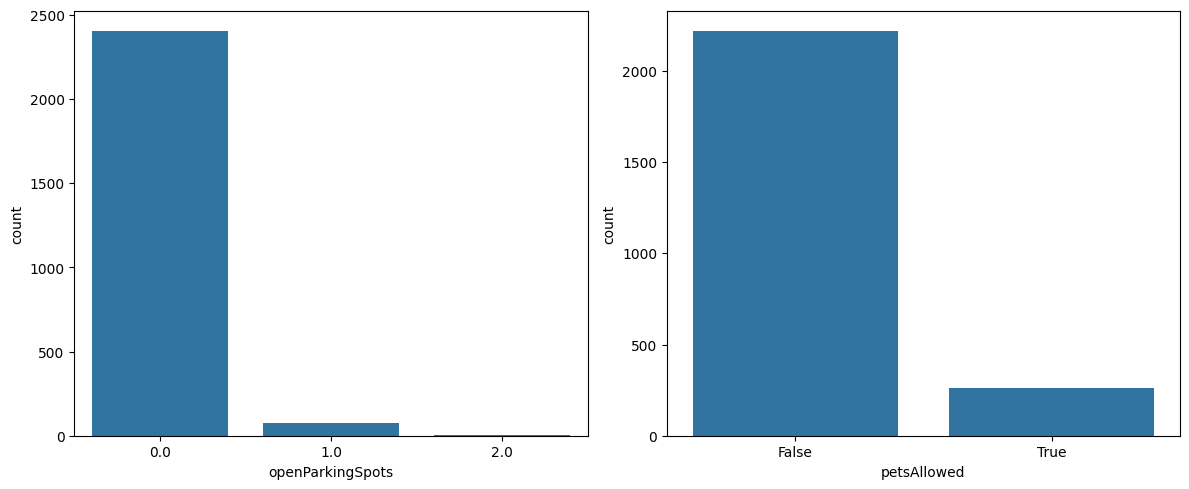

In [12]:
# Create plots for variables with a high amount of missing values
df_copy = df.copy()
df_copy['openParkingSpots'] = df_copy['openParkingSpots'].fillna(0)
df_copy['petsAllowed'] = df_copy['petsAllowed'].fillna('False')

other_features = ['openParkingSpots', 'petsAllowed']

plt.figure(figsize=(12,5))
for i, col in enumerate(other_features):
    plt.subplot(1, 2, i+1)
    sns.countplot(data=df_copy, x=col)
    plt.xlabel(col)
    
plt.tight_layout()
plt.show()


- The vast majority of the apartments don't have an available parking spot nearby.
- The vast majority of the apartments don't allow pets.


---

## Bivariate Analysis – Continuous Features vs. Price

Now we shift from univariate to **bivariate analysis** examining how individual features relate to our target variable, `price`. We start with three continuous or near-continuous features: `areaSqm` (apartment size in square metres), `renovationYear`, and `yearBuilt`. Scatter plots are ideal here because they reveal both the overall trend and the presence of **outliers** that deviate from the main cloud of points.

Outlier detection at this stage is qualitative. We are simply flagging points that look suspicious so we can apply a more rigorous treatment during preprocessing.


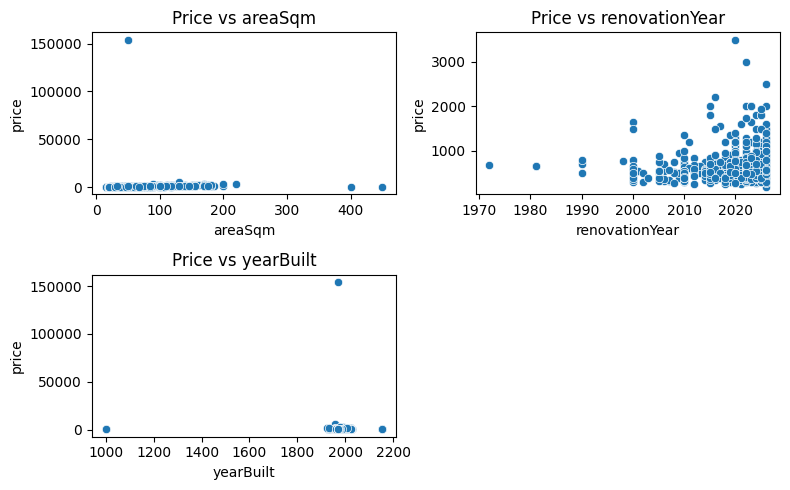

In [13]:
features_subset2 = ['areaSqm', 'renovationYear', 'yearBuilt']
plt.figure(figsize=(8,5))

for i, feat in enumerate(features_subset2):
    plt.subplot(2, 2, i+1)
    sns.scatterplot(data=df, x=feat, y="price")
    plt.title(f'Price vs {feat}')

plt.tight_layout()
plt.show()


`areaSqm`, `renovationYear` and `yearBuilt` seem to be related with `price` so we need to investigate these relationships more. Although there are some outliers that are present in the `areaSqm` and `yearBuilt` variables and need to be removed later on.


## Descriptive Statistics for Numeric Features


In [14]:
# Select numeric features for analysis
df_num = df.select_dtypes(include = ["float64", "int64"])
df_num.describe().T


,count,mean,std,min,25%,50%,75%,max
listingId,2480.0,1.948169e+07,2.112960e+06,782706.0,19791317.25,20148990.50,2.029425e+07,20383704.0
areaSqm,2480.0,5.507016e+01,2.990256e+01,15.0,35.00,47.00,6.900000e+01,450.0
bathrooms,2415.0,1.032712e+00,1.935323e-01,1.0,1.00,1.00,1.000000e+00,5.0
closedParkingSpots,6.0,6.666667e-01,5.163978e-01,0.0,0.25,1.00,1.000000e+00,1.0
floor,2480.0,7.045565e+00,2.520097e+00,0.0,6.00,7.00,9.000000e+00,15.0
kitchens,2294.0,1.001744e+00,4.173006e-02,1.0,1.00,1.00,1.000000e+00,2.0
livingRooms,2062.0,1.006305e+00,8.507793e-02,1.0,1.00,1.00,1.000000e+00,3.0
openParkingSpots,83.0,9.759036e-01,2.694124e-01,0.0,1.00,1.00,1.000000e+00,2.0
price,2480.0,6.554375e+02,3.093590e+03,190.0,450.00,550.00,6.500000e+02,154000.0
pricePerSqm,2480.0,1.311320e+01,6.173086e+01,1.0,8.97,11.32,1.423500e+01,3080.0


It seems that the minimum price for an apartment in our dataset is 190€ but we can also see that the maximum value is very high. Also there are some non-logical values regarding `yearBuilt`. The minimum value is 1000 while the maximum is 2155. These are clearly data-entry errors that will need to be corrected during preprocessing.


---

## Correlation Analysis – Pearson vs. Spearman

Correlation analysis is a cornerstone of EDA for regression tasks because it quantifies the strength and direction of the linear (or monotonic) relationship between each feature and the target. We start with the **Pearson correlation coefficient**, which measures *linear* association. A value close to +1 or −1 indicates a strong positive or negative linear relationship, while a value near 0 suggests no linear relationship.

The heatmap below visualises the full Pearson correlation matrix for all numeric features.


## Pearson

<Axes: >

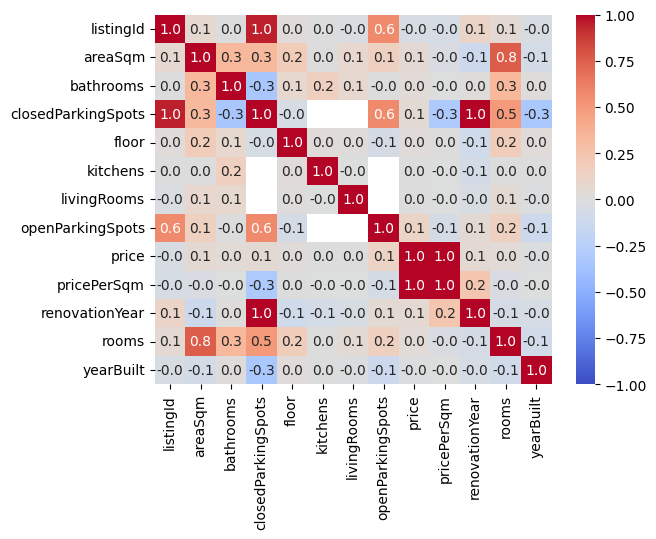

In [15]:
# correlation matrix
sns.heatmap(df_num.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0, fmt=".1f")


At first glance we see that `price` is only correlated with `pricePerSqm` and has zero correlation with the other variables. That is a bit confusing isn't it? One possible reason to why this is happening is because we are using `.corr()` which calculates the Pearson coefficient by default. That means we assume a **linear relationship** between our target variable and our independent variables. In real-world scenarios like this one there are more complex, non-linear relationships between the data. Also there are some empty cells in the matrix indicating NaN values which can be explained by the large amount of NaN values in some of the variables.

Now let's continue by calculating the **Spearman** coefficient, which captures *non-linear* relationships, and see what happens.


### Spearman


<Axes: >

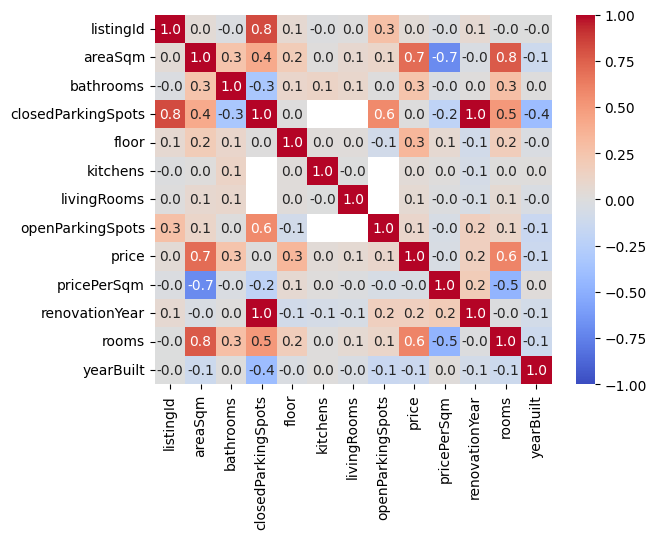

In [16]:
# correlation matrix
sns.heatmap(df_num.corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0, fmt=".1f")


Now things get more clear! We can already see that `price` is highly correlated with `areaSqm` and there is also a moderate correlation with `rooms`. The correlation is positive which means that if one variable increases the other also increases. Also there are some variables that are highly correlated with each other like `renovationYear` and `closedParkingSpots`. Later on we should exclude some of them in order to reduce **multicollinearity**, a condition where two or more predictors are strongly correlated with each other, which can inflate variance and make coefficient estimates unstable in linear models. We can continue by investigating how `price` changes regarding `bathrooms`, `floor` and `rooms`.


---

## Categorical Features vs. Price – Bar Plots

Bar plots are an effective way to compare the **average price** across different categories of a feature. By plotting the mean price for each value of `bathrooms`, `floor`, and `rooms`, we can quickly see whether adding a bathroom, living on a higher floor, or having more bedrooms translates into a higher rent. The error bars in each bar represent the 95% confidence interval around the mean, giving us a sense of how much prices vary within each category.


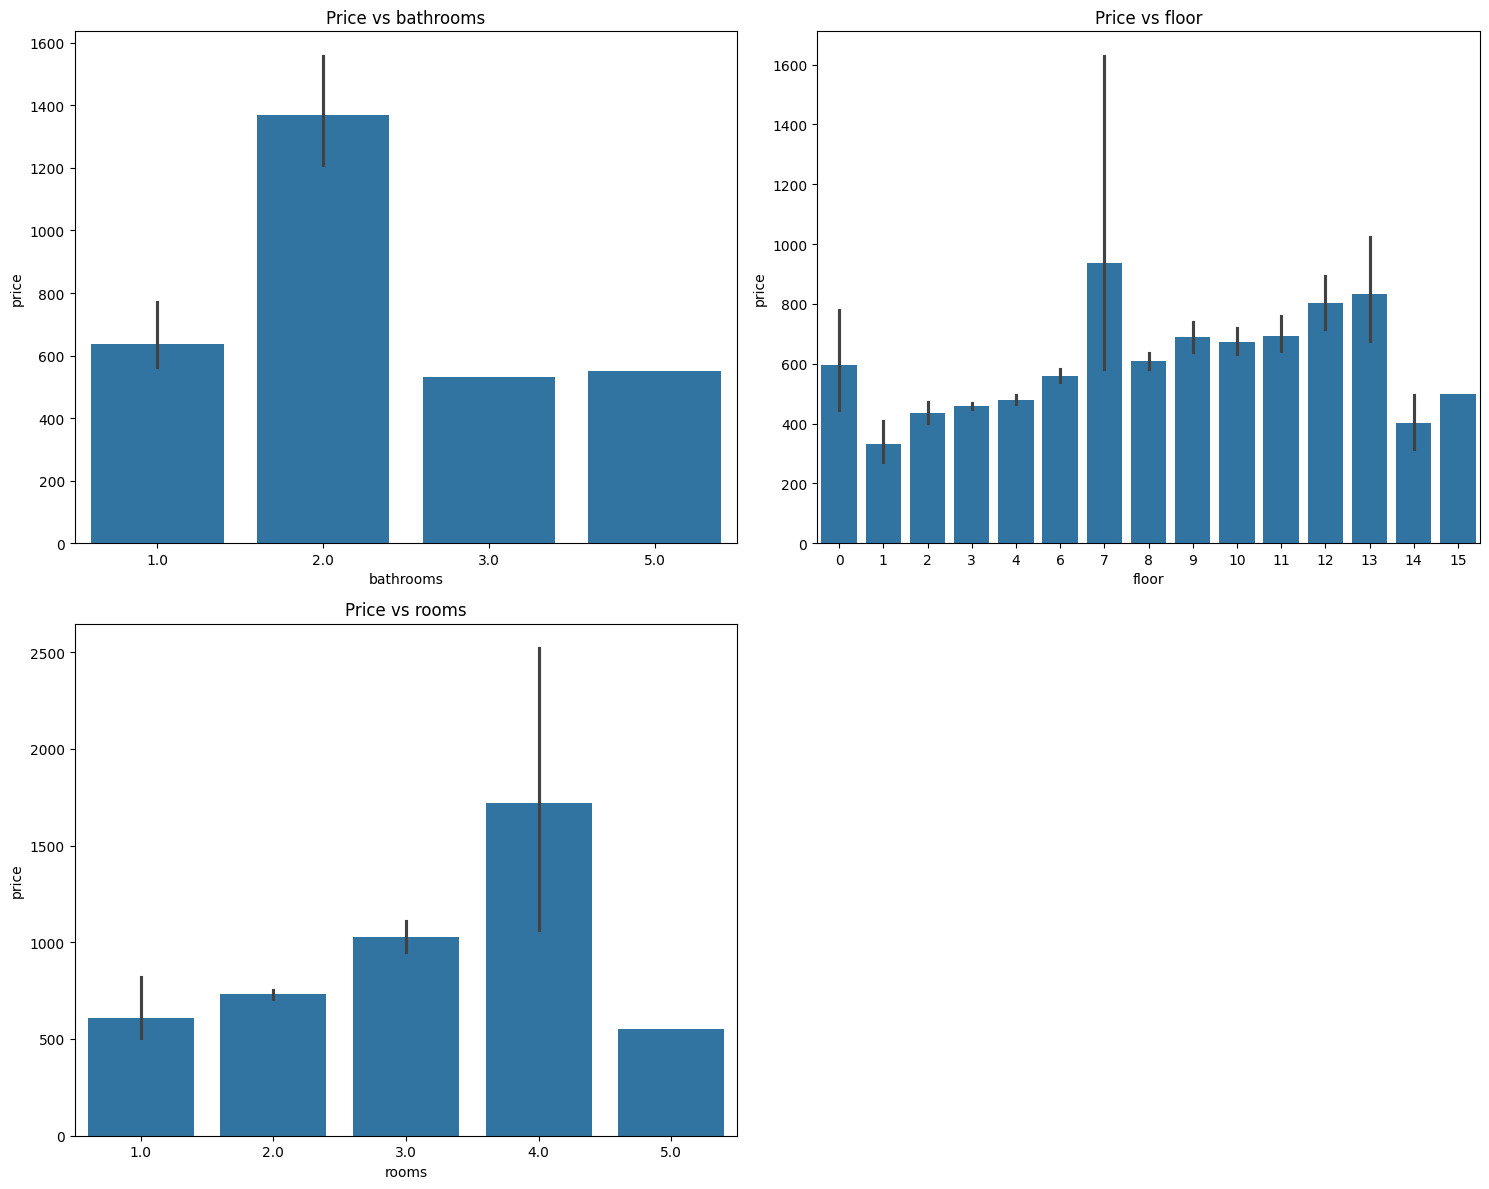

In [17]:
correlated_features = ['bathrooms', 'floor', 'rooms']
plt.figure(figsize=(15,12))

for i, col in enumerate(correlated_features):
    plt.subplot(2, 2, i+1)
    sns.barplot(data=df, x=col, y="price")
    plt.title(f'Price vs {col}')

plt.tight_layout()
plt.show()


From the plots above we can derive some conclusions:
- The price of an apartment is higher if it has two bathrooms instead of one (we are not looking at apartments with 3 or 5 bathrooms as there are few examples in the dataset).
- Apartments located on the 7th floor are the most expensive and price tends to get higher as the floor number increases (we are not interested for 0 and 1st floor as they contain very little examples).
- The price of an apartment increases with the number of bedrooms (we are only interested in apartments with 3 bedrooms at most).


## Binary & Amenity Features vs. Price

Beyond the structural features (size, rooms, floor), apartments come with a set of **amenities** like air conditioning, fireplace, elevator, garden, and so on. These are mostly binary features. To assess whether any of these amenities carry a meaningful price premium, we plot the average rent for apartments that have or do not have each amenity. Features where the two bars are nearly identical are unlikely to be strong predictors on their own, though they may still contribute in combination with other variables.


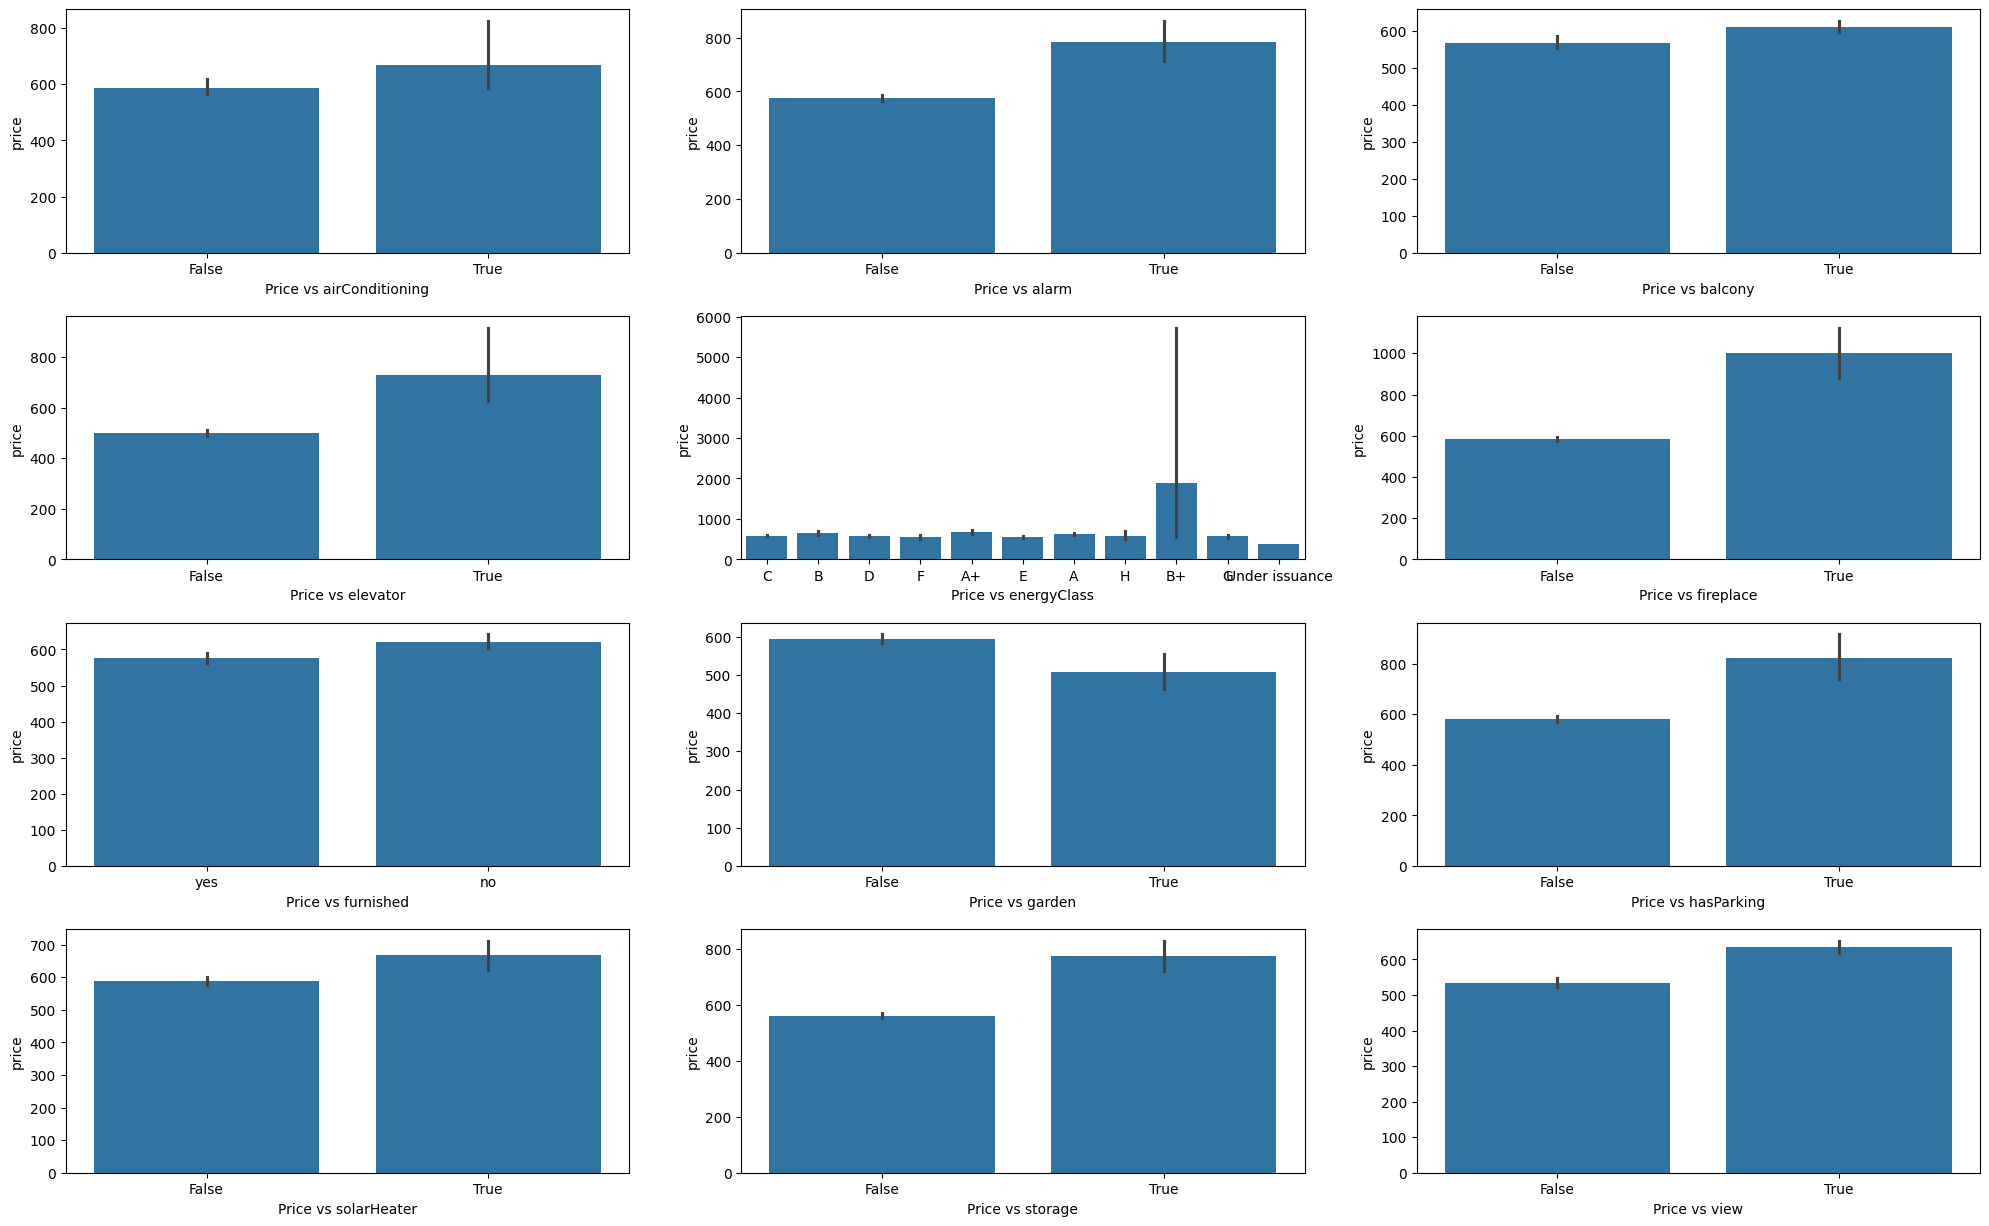

In [18]:
features_subset3 = ['airConditioning', 'alarm', 'balcony', 'elevator', 'energyClass',
       'fireplace', 'furnished', 'garden', 'hasParking',
       'solarHeater', 'storage', 'view']

plt.figure(figsize=(20, 15))

for i, col in enumerate(features_subset3):
    plt.subplot(5, 3, i+1)
    sns.barplot(data=df, x=col, y="price")
    plt.xlabel(f'Price vs {col}')

plt.tight_layout()
plt.show()


Regarding binary features (True or False) we do not see a big difference in the price range. When it comes to the energy class we notice that apartments with B+ energy class tend to be more expensive although their price is characterized by a lot of variance.


---

## Location & District vs. Price

We now turn our attention back to the location-related features we engineered earlier. A horizontal bar plot of average rent by `location_floor` gives a clear ranking of neighbourhoods by price. This kind of visualisation is useful for confirming domain knowledge (e.g., city-centre apartments should be more expensive) and for identifying any surprising patterns that might warrant further investigation.

After that, we aggregate the 12 location floors into 5 municipal districts to obtain a higher-level view of how rent varies across Thessaloniki's administrative divisions.


Text(0.5, 1.0, 'Location floor vs Price')

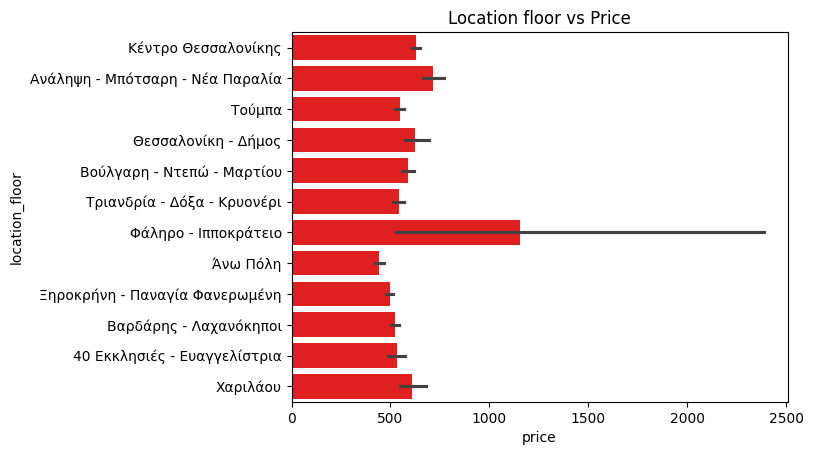

In [19]:
bar = sns.barplot(data=df, x="price", y="location_floor", color="red")
bar.set_title("Location floor vs Price")


Regarding `location_floor` we can generally see a balance in the price of apartments except for those located in the Faliro-Ippokrateio area (although their price contains a lot of variance). The next most expensive area is 'Analipsi-Mpotsari-Nea Paralia' while the area with the cheapest apartments to rent is 'Ano Poli'.

We can also map the locations to districts (5 in total) to see how the price is distributed.


### Mapping to Municipal Districts

To further reduce the granularity of the location feature, we define a manual mapping from each of the 12 `location_floor` values to one of five municipal districts. Districts are numbered 1–5. This numeric encoding can later be treated as an ordinal feature or one-hot encoded, depending on the model we choose.


In [20]:
location_to_district = {
    "Κέντρο Θεσσαλονίκης": 1,
    "Φάληρο - Ιπποκράτειο": 1,
    "Τούμπα": 4,
    "Ανάληψη - Μπότσαρη - Νέα Παραλία": 5,
    "Θεσσαλονίκη - Δήμος": 1,
    "Βούλγαρη - Ντεπώ - Μαρτίου": 5,
    "Βαρδάρης - Λαχανόκηποι": 1,
    "Ξηροκρήνη - Παναγία Φανερωμένη": 2,
    "Τριανδρία - Δόξα - Κρυονέρι": 4,
    "Άνω Πόλη": 1,
    "40 Εκκλησίες - Ευαγγελιστρίας": 3,
    "Χαριλάου": 5
}


In [21]:
df["district"] = df["location_floor"].map(location_to_district)


In [22]:
df["district"].head()


0    1.0
1    1.0
2    5.0
3    5.0
4    4.0
Name: district, dtype: float64

Text(0.5, 1.0, 'Price vs district')

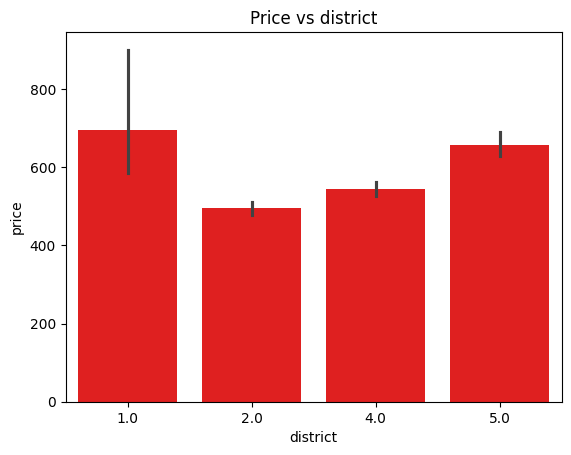

In [23]:
bar = sns.barplot(data=df, x="district", y="price", color="red")
bar.set_title("Price vs district")


Regarding `district` we can observe that apartments which belong in the 1st district are the most expensive followed by those located in the 5th district.

This is consistent with the fact that District 1 encompasses the city centre and its immediate surroundings, where demand and consequently rents are highest.


---

## Next Steps

This exploratory data analysis has revealed several important insights that will guide the preprocessing and modelling phases. The next notebook will cover **data preprocessing** before training the prediction model.
